## Классификация редких событий (Imbalanced Rare-Hit Classification)

Условия дизбаланса

1. **Стратифицированное разбиение (`Stratified Split`)**: сохранение точной пропорции редкого класса в обучающей и тестовой выборках.
2. **Обогащение признаками аномалий**: используем непрерывный скор `score_iforest`, найденный на этапе поиска аномалий без учителя.
3. **Градиентный бустинг со взвешиванием классов (`class_weight='balanced'`)**.
4. **Метрики качества для редких событий**: Precision-Recall AUC (PR-AUC), ROC-AUC и матрица стоимости ошибок (Cost Matrix).

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Загрузка обогащенного датасета из Фазы 2
df = pd.read_csv('data/movies_with_anomalies.csv')
print(f"Датасет успешно загружен: {len(df):,} строк, {df.shape[1]} колонок")

# 2. Формирование признаков X и целевой переменной y
# Включаем базовые признаки фильма + скор аномальности из Isolation Forest
feature_cols = [
    'runtimeMinutes',
    'movie_age',
    'log_votes',
    'rating_to_log_votes',
    'score_iforest'
]

X = df[feature_cols].copy()
y = df['is_masterpiece'].copy()

# 3. Анализ экстремального дисбаланса классов
pos_count = y.sum()
neg_count = len(y) - pos_count
print(f"\nАнализ дисбаланса классов (целевая метка is_masterpiece):")
print(f"  Класс 0 (Обычные фильмы): {neg_count:,} ({neg_count / len(y):.2%})")
print(f"  Класс 1 (Редкие шедевры): {pos_count:,} ({pos_count / len(y):.3%})")
print(f"  Соотношение классов:      1 : {neg_count // pos_count}")

# 4. Стратифицированное разбиение на Train (80%) и Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.8,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"\nРазмеры выборок после стратификации:")
print(f"  Train: {X_train.shape[0]:,} объектов (из них редких событий: {y_train.sum():,}, {y_train.mean():.3%})")
print(f"  Test:  {X_test.shape[0]:,} объектов (из них редких событий: {y_test.sum():,}, {y_test.mean():.3%})")

Датасет успешно загружен: 313,025 строк, 15 колонок

Анализ дисбаланса классов (целевая метка is_masterpiece):
  Класс 0 (Обычные фильмы): 312,470 (99.82%)
  Класс 1 (Редкие шедевры): 555 (0.177%)
  Соотношение классов:      1 : 563

Размеры выборок после стратификации:
  Train: 250,420 объектов (из них редких событий: 444, 0.177%)
  Test:  62,605 объектов (из них редких событий: 111, 0.177%)


### 2. Обучение градиентного бустинга (HistGradientBoosting) и анализ важности признаков
Обучаем современный гистограммный бустинг со взвешиванием классов:
- **`class_weight='balanced'`**: автоматически рассчитывает штрафы за ошибку обратно пропорционально частотам классов (в 563 раза сильнее наказывает за пропуск шедевра).
- **Permutation Importance**: честно оцениваем реальный вклад каждого признака в итоговый PR-AUC на тестовой выборке.

In [7]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

# 1. Инициализация модели гистограммного бустинга со взвешиванием классов
clf = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=42
)

# 2. Обучение модели на обучающей выборке
t0 = time.time()
clf.fit(X_train, y_train)
print(f"Модель успешно обучена за {time.time() - t0:.2f} сек на {X_train.shape[0]:,} объектах!")

# 3. Оценка важности признаков (Permutation Importance) по метрике PR-AUC (Average Precision)
perm_importance = permutation_importance(
    clf, X_test, y_test,
    scoring='average_precision',
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values('Importance_Mean', ascending=False)

print("\nВажность признаков (падение PR-AUC при случайном перемешивании признака):")
display(importance_df.round(4))


Модель успешно обучена за 0.58 сек на 250,420 объектах!

Важность признаков (падение PR-AUC при случайном перемешивании признака):


,Feature,Importance_Mean,Importance_Std
2,log_votes,0.9920,0.0035
3,rating_to_log_votes,0.7929,0.0133
4,score_iforest,0.0498,0.0141
0,runtimeMinutes,0.0004,0.0007
1,movie_age,-0.0002,0.0008


### 3. Комплексная оценка качества: PR-AUC, ROC-AUC и матрица ошибок
Проводим глубокую диагностику модели на отложенной тестовой выборке (62,605 фильмов, из них 111 редких шедевров):
1. **`predict_proba`**: получаем калиброванные непрерывные вероятности $P(y=1|X)$.
2. **PR-AUC (Average Precision)**: рассчитываем площадь под Precision-Recall кривой и сопоставляем с базовой линией случайного угадывания ($0.18\%$).
3. **ROC-AUC**: измеряем глобальную разделимость классов (сравнение с монеткой $50\%$).
4. **Confusion Matrix**: строим тепловую карту матрицы ошибок ($TP, TN, FP, FN$) при стандартном пороге $\tau = 0.5$.

PR-AUC (Average Precision): 0.9953  (Случайный baseline: 0.0018)
ROC-AUC:                   1.0000  (Случайный baseline: 0.5000)


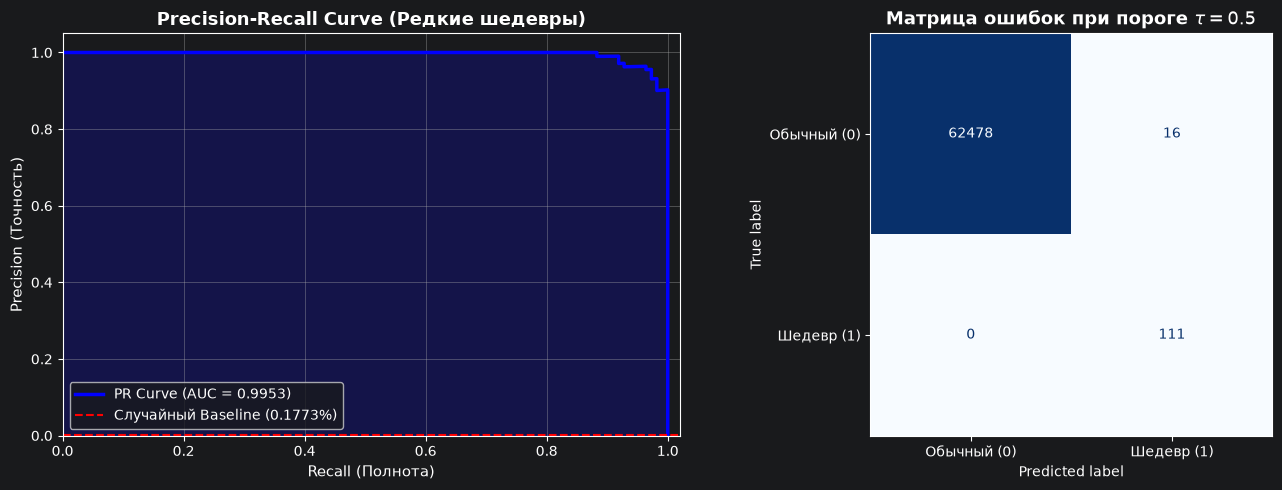


Подробный отчет классификации (дефолтный порог tau = 0.5):
                    precision    recall  f1-score   support

Обычные фильмы (0)     1.0000    0.9997    0.9999     62494
       Шедевры (1)     0.8740    1.0000    0.9328       111

          accuracy                         0.9997     62605
         macro avg     0.9370    0.9999    0.9663     62605
      weighted avg     0.9998    0.9997    0.9998     62605



In [11]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# 1. Получение непрерывных вероятностей и бинарных прогнозов при дефолтном пороге tau = 0.5
y_pred_proba = clf.predict_proba(X_test)[:, 1]
y_pred_default = clf.predict(X_test)

# 2. Расчет интегральных метрик качества
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)
baseline_pr = y_test.mean()


print(f"PR-AUC (Average Precision): {pr_auc:.4f}  (Случайный baseline: {baseline_pr:.4f})")
print(f"ROC-AUC:                   {roc_auc:.4f}  (Случайный baseline: 0.5000)")

# 3. Визуализация: Precision-Recall Curve и Confusion Matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: Precision-Recall Curve
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_pred_proba)
ax1.plot(recall_vals, precision_vals, color='blue', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.4f})')
ax1.axhline(baseline_pr, color='red', linestyle='--', lw=1.5, label=f'Случайный Baseline ({baseline_pr:.4%})')
ax1.fill_between(recall_vals, precision_vals, alpha=0.2, color='blue')
ax1.set_xlabel('Recall (Полнота)', fontsize=11)
ax1.set_ylabel('Precision (Точность)', fontsize=11)
ax1.set_title('Precision-Recall Curve (Редкие шедевры)', fontsize=13, fontweight='bold')
ax1.set_xlim([0.0, 1.02])
ax1.set_ylim([0.0, 1.05])
ax1.grid()
ax1.legend(loc='lower left', fontsize=10)

# Правый график: Confusion Matrix (tau = 0.5)
cm = confusion_matrix(y_test, y_pred_default)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Обычный (0)', 'Шедевр (1)'])
disp.plot(ax=ax2, cmap='Blues', values_format='d', colorbar=False)
ax2.set_title('Матрица ошибок при пороге $\\tau = 0.5$', fontsize=13, fontweight='bold')
ax2.grid(False)

plt.tight_layout()
plt.show()

# 4. Детальный классификационный отчет
print("\nПодробный отчет классификации (дефолтный порог tau = 0.5):")
print(classification_report(y_test, y_pred_default, digits=4, target_names=['Обычные фильмы (0)', 'Шедевры (1)']))
